In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

In [6]:
# 1. Load & Pre-process the dataset
df = pd.read_csv('uber.csv')
df = df.dropna()    # drop rows with missing data

df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [7]:
df = df[['fare_amount','pickup_longitude','pickup_latitude','dropoff_longitude','dropoff_latitude','passenger_count']]

df['distance'] = np.sqrt((df['dropoff_latitude'] - df['pickup_latitude'])**2 + (df['dropoff_longitude'] - df['pickup_longitude'])**2)
# sqrt of ( drop_latitude - pick_latitude)** 2 + (drop_longitude - pick_longitude)**2 )

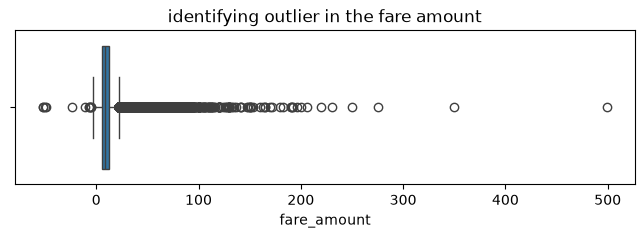

In [20]:
# 2. Identify Outliers
plt.figure(figsize=(8,2))
sns.boxplot(x=df['fare_amount'])
plt.title('identifying outlier in the fare amount')
plt.show()

#remove the outliers
df_clean = df[(df['fare_amount'] > 0 ) & (df['fare_amount'] < 100)]

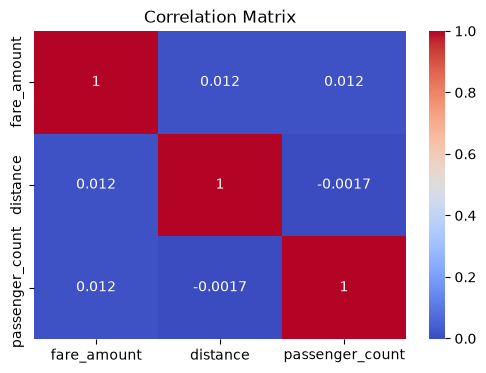

In [25]:
# 3. Check the Correlation
plt.figure(figsize=(6,4))
sns.heatmap(df_clean[['fare_amount', 'distance', 'passenger_count']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [27]:
#4 implement linear and ridge
X = df_clean[['distance', 'passenger_count']]
Y = df_clean['fare_amount']

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, random_state=42)

models = {
    'Linear Regression':LinearRegression(),
    'Ridge Regression':Ridge(),
    'Lasso Regression':Lasso()
}

for name, model in models.items():
    model.fit(x_train,y_train)
    y_pred = model.predict(x_test)

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    print(f"{name}:")
    print(f" R2 Score : {r2:.4f}")
    print(f" RMSE     : {rmse:.2f}")

Linear Regression:
 R2 Score : -0.0042
 RMSE     : 9.36
Ridge Regression:
 R2 Score : -0.0042
 RMSE     : 9.36
Lasso Regression:
 R2 Score : 0.0000
 RMSE     : 9.34
